# EN3150 Assignment 03: SOTA Fine-Tuning and Final Trade-off Comparison

This notebook covers:
1. **Step 5: SOTA Fine-Tuning & Evaluation**
   - Selects two industry-standard lightweight mobile/edge architectures: **MobileNetV2** and **EfficientNet-B0**.
   - Adapts our `(64, 64, 1)` grayscale OCTMNIST pipeline to 3-channel inputs with model-specific preprocessing layers inside the computation graph.
   - Fine-tunes both models on the identical 70/15/15 OCTMNIST splits and evaluates them on the deduplicated test set (`15,172` images), reporting **Test Accuracy, Precision, Recall, F1-Score, Confusion Matrices, Total Parameter Count, and Model Size (MB)**.
2. **Step 6: Final Comparison & Trade-off Discussion**
   - Compares our custom resource-constrained **Model B (19,885 parameters, < 0.08 MB)** against **Model A**, **MobileNetV2**, and **EfficientNet-B0**.
   - Critically analyzes the balance between **Accuracy, Memory Footprint, and Computational Cost** across microcontroller (MCU) and embedded edge-node deployment targets.

In [5]:
import os
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset import load_octmnist_datasets, SEED, DEFAULT_BATCH_SIZE, NUM_CLASSES
from src.models import (
    build_model_a,
    build_model_b,
    build_mobilenetv2_sota,
    build_efficientnetb0_sota,
)

tf.random.set_seed(SEED)
np.random.seed(SEED)

print(f"TensorFlow version: {tf.__version__}")
print(f"Available GPUs    : {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.21.0
Available GPUs    : []


In [6]:
# Load identical OCTMNIST datasets and evaluation arrays
(train_ds, val_ds, test_ds), (X_train, y_train, X_val_eval, y_val_eval, X_test_eval, y_test_eval), info = (
    load_octmnist_datasets(batch_size=DEFAULT_BATCH_SIZE)
)

class_names = [info["label"][str(i)] for i in range(NUM_CLASSES)]
short_class_names = ["CNV", "DME", "Drusen", "Normal"]

print(f"Training samples   : {len(X_train):,}")
print(f"Validation samples : {len(X_val_eval):,}")
print(f"Testing samples    : {len(X_test_eval):,}")

Training samples   : 76,128
Validation samples : 15,170
Testing samples    : 15,172


---
## Step 5: SOTA Fine-Tuning & Evaluation

### 5.1 Selected Pre-Trained Lightweight Architectures
1. **MobileNetV2** (Sandler et al., CVPR 2018):
   - Designed specifically for mobile and embedded vision applications.
   - Introduces **Inverted Residual Blocks** (`MBConv`) with **Linear Bottlenecks** and `ReLU6` activations ($\min(\max(0, x), 6)$), expanding low-dimensional compressed representations via $1 \times 1$ pointwise convolutions, filtering spatially with $3 \times 3$ depthwise convolutions, and projecting back to a linear bottleneck.
2. **EfficientNet-B0** (Tan & Le, ICML 2019):
   - Developed via neural architecture search (NAS) optimizing both accuracy and FLOPs, using **Compound Scaling** of depth, width, and resolution.
   - Uses `MBConv` blocks augmented with **Squeeze-and-Excitation (SE)** channel-attention gates and **Swish (`SiLU`)** activations ($x \cdot \sigma(x)$).

### 5.2 Input Adaptation for $64 \times 64 \times 1$ Grayscale OCT Scans
Because ImageNet pre-trained weights expect 3-channel RGB inputs with specific pixel value ranges:
- A `Concatenate` layer repeats the `(64, 64, 1)` grayscale tensor across 3 channels $\rightarrow (64, 64, 3)$.
- For **MobileNetV2**, a `Rescaling(scale=2.0, offset=-1.0)` layer maps $[0, 1] \rightarrow [-1, 1]$.
- For **EfficientNet-B0**, a `Rescaling(scale=255.0, offset=0.0)` layer maps $[0, 1] \rightarrow [0, 255]$ as expected by EfficientNet-B0's internal normalization layers.
- Both backbones are topped with `GlobalAveragePooling2D`, `Dropout(0.3)`, and a 4-class `Dense(..., activation='softmax')` head.

In [7]:
mobilenet_v2 = build_mobilenetv2_sota(input_shape=(64, 64, 1), num_classes=NUM_CLASSES, fine_tune_at=100)
efficientnet_b0 = build_efficientnetb0_sota(input_shape=(64, 64, 1), num_classes=NUM_CLASSES, fine_tune_at=150)

for m in [mobilenet_v2, efficientnet_b0]:
    total_p = m.count_params()
    trainable_p = sum(int(np.prod(w.shape)) for w in m.trainable_weights)
    non_trainable_p = total_p - trainable_p
    fp32_mb = (total_p * 4) / (1024 ** 2)
    print("=" * 70)
    print(f"Model: {m.name}")
    print(f"  Total Parameters        : {total_p:,}")
    print(f"  Trainable Parameters    : {trainable_p:,}")
    print(f"  Non-Trainable Parameters: {non_trainable_p:,}")
    print(f"  FP32 Weight Size (MB)   : {fp32_mb:.2f} MB")

Model: MobileNetV2_FineTuned
  Total Parameters        : 2,263,108
  Trainable Parameters    : 1,866,564
  Non-Trainable Parameters: 396,544
  FP32 Weight Size (MB)   : 8.63 MB
Model: EfficientNetB0_FineTuned
  Total Parameters        : 4,054,695
  Trainable Parameters    : 3,292,828
  Non-Trainable Parameters: 761,867
  FP32 Weight Size (MB)   : 15.47 MB


In [8]:
SOTA_EPOCHS = 10
SOTA_LR = 1e-4  # Lower learning rate for fine-tuning pre-trained weights

mobilenet_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=SOTA_LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("=" * 70)
print(f"Fine-Tuning {mobilenet_v2.name} for {SOTA_EPOCHS} epochs...")
print("=" * 70)
t0 = time.perf_counter()
hist_mobilenet = mobilenet_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=SOTA_EPOCHS,
    verbose=1,
)
time_mobilenet = (time.perf_counter() - t0) / SOTA_EPOCHS

mobilenet_path = PROJECT_ROOT / "data" / "sota_mobilenetv2.keras"
mobilenet_v2.save(mobilenet_path)
mobilenet_disk_mb = os.path.getsize(mobilenet_path) / (1024 ** 2)
print(f"\nSaved MobileNetV2 to {mobilenet_path} ({mobilenet_disk_mb:.2f} MB)")
print(f"Average training time per epoch: {time_mobilenet:.2f} s")

Fine-Tuning MobileNetV2_FineTuned for 10 epochs...
Epoch 1/10


c:\Users\nadun\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


   2379/Unknown 182s 73ms/step - accuracy: 0.8312 - loss: 0.5033

c:\Users\nadun\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2379/2379 ━━━━━━━━━━━━━━━━━━━━ 197s 79ms/step - accuracy: 0.8312 - loss: 0.5033 - val_accuracy: 0.8898 - val_loss: 0.4017
Epoch 2/10
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 184s 77ms/step - accuracy: 0.8938 - loss: 0.3144 - val_accuracy: 0.9045 - val_loss: 0.3234
Epoch 3/10
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 164s 69ms/step - accuracy: 0.9167 - loss: 0.2458 - val_accuracy: 0.9090 - val_loss: 0.3078
Epoch 4/10
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 164s 69ms/step - accuracy: 0.9280 - loss: 0.2056 - val_accuracy: 0.9076 - val_loss: 0.2970
Epoch 5/10
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 165s 69ms/step - accuracy: 0.9403 - loss: 0.1718 - val_accuracy: 0.9117 - val_loss: 0.2654
Epoch 6/10
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 164s 69ms/step - accuracy: 0.9490 - loss: 0.1457 - val_accuracy: 0.9225 - val_loss: 0.2775
Epoch 7/10
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 163s 68ms/step - accuracy: 0.9563 - loss: 0.1229 - val_accuracy: 0.9221 - val_loss: 0.2853
Epoch 8/10
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 164s 69ms/step - accuracy: 0.9624 - lo

In [9]:
efficientnet_b0.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=SOTA_LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("=" * 70)
print(f"Fine-Tuning {efficientnet_b0.name} for {SOTA_EPOCHS} epochs...")
print("=" * 70)
t0 = time.perf_counter()
hist_efficientnet = efficientnet_b0.fit(
    train_ds,
    validation_data=val_ds,
    epochs=SOTA_EPOCHS,
    verbose=1,
)
time_efficientnet = (time.perf_counter() - t0) / SOTA_EPOCHS

efficientnet_path = PROJECT_ROOT / "data" / "sota_efficientnetb0.keras"
efficientnet_b0.save(efficientnet_path)
efficientnet_disk_mb = os.path.getsize(efficientnet_path) / (1024 ** 2)
print(f"\nSaved EfficientNet-B0 to {efficientnet_path} ({efficientnet_disk_mb:.2f} MB)")
print(f"Average training time per epoch: {time_efficientnet:.2f} s")

Fine-Tuning EfficientNetB0_FineTuned for 10 epochs...
Epoch 1/10
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 485s 194ms/step - accuracy: 0.8468 - loss: 0.4381 - val_accuracy: 0.9081 - val_loss: 0.2738
Epoch 2/10
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 596s 250ms/step - accuracy: 0.9035 - loss: 0.2819 - val_accuracy: 0.9203 - val_loss: 0.2403
Epoch 3/10
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 556s 232ms/step - accuracy: 0.9217 - loss: 0.2284 - val_accuracy: 0.9251 - val_loss: 0.2241
Epoch 4/10
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 402s 168ms/step - accuracy: 0.9336 - loss: 0.1943 - val_accuracy: 0.9291 - val_loss: 0.2141
Epoch 5/10
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 284s 119ms/step - accuracy: 0.9415 - loss: 0.1683 - val_accuracy: 0.9301 - val_loss: 0.2187
Epoch 6/10
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 282s 118ms/step - accuracy: 0.9482 - loss: 0.1491 - val_accuracy: 0.9337 - val_loss: 0.2093
Epoch 7/10
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 284s 119ms/step - accuracy: 0.9556 - loss: 0.1272 - val_accuracy: 0.9290 - val_loss: 0.2209
Epoch 8/

In [10]:
def evaluate_sota_model(model, test_dataset, y_true, label):
    test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
    y_prob = model.predict(test_dataset, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred)

    print("=" * 70)
    print(f"TEST SET EVALUATION: {label}")
    print("=" * 70)
    print(f"Total Parameters : {model.count_params():,}")
    print(f"FP32 Size (MB)   : {(model.count_params() * 4) / (1024 ** 2):.2f} MB")
    print(f"Test Loss        : {test_loss:.4f}")
    print(f"Test Accuracy    : {test_acc * 100:.2f}%")
    print(f"Macro Precision  : {prec_macro * 100:.2f}%")
    print(f"Macro Recall     : {rec_macro * 100:.2f}%")
    print(f"Macro F1-Score   : {f1_macro * 100:.2f}%\n")
    print(classification_report(y_true, y_pred, target_names=short_class_names, digits=4))

    return {
        "test_loss": test_loss,
        "test_acc": test_acc,
        "prec_macro": prec_macro,
        "rec_macro": rec_macro,
        "f1_macro": f1_macro,
        "cm": cm,
    }

eval_mobilenet = evaluate_sota_model(mobilenet_v2, test_ds, y_test_eval, "MobileNetV2 (Fine-Tuned)")
eval_efficientnet = evaluate_sota_model(efficientnet_b0, test_ds, y_test_eval, "EfficientNet-B0 (Fine-Tuned)")

TEST SET EVALUATION: MobileNetV2 (Fine-Tuned)
Total Parameters : 2,263,108
FP32 Size (MB)   : 8.63 MB
Test Loss        : 0.3173
Test Accuracy    : 92.56%
Macro Precision  : 89.88%
Macro Recall     : 84.08%
Macro F1-Score   : 86.52%

              precision    recall  f1-score   support

         CNV     0.9220    0.9697    0.9452      4751
         DME     0.9597    0.8393    0.8955      1674
      Drusen     0.7743    0.5828    0.6651      1201
      Normal     0.9390    0.9715    0.9550      7546

    accuracy                         0.9256     15172
   macro avg     0.8988    0.8408    0.8652     15172
weighted avg     0.9229    0.9256    0.9224     15172



c:\Users\nadun\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


TEST SET EVALUATION: EfficientNet-B0 (Fine-Tuned)
Total Parameters : 4,054,695
FP32 Size (MB)   : 15.47 MB
Test Loss        : 0.2286
Test Accuracy    : 93.42%
Macro Precision  : 88.85%
Macro Recall     : 87.80%
Macro F1-Score   : 88.30%

              precision    recall  f1-score   support

         CNV     0.9564    0.9602    0.9583      4751
         DME     0.9258    0.9170    0.9214      1674
      Drusen     0.7177    0.6711    0.6936      1201
      Normal     0.9541    0.9636    0.9588      7546

    accuracy                         0.9342     15172
   macro avg     0.8885    0.8780    0.8830     15172
weighted avg     0.9330    0.9342    0.9335     15172



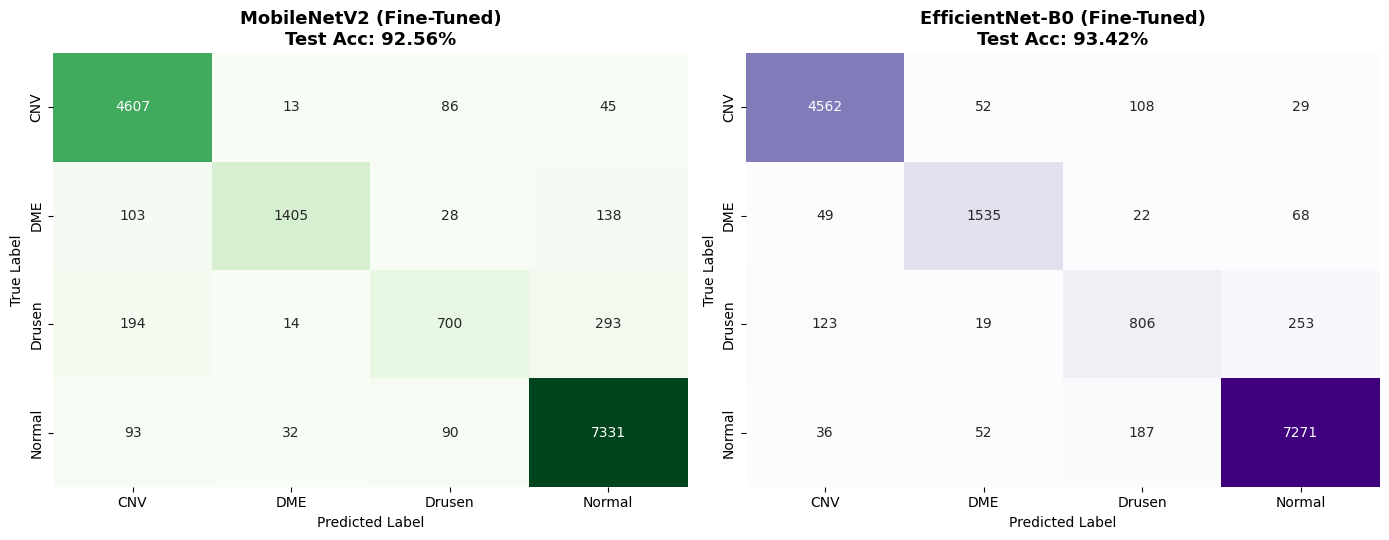

In [11]:
# Plot Confusion Matrices for MobileNetV2 and EfficientNet-B0
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, res, title, cmap in [
    (axes[0], eval_mobilenet, f"MobileNetV2 (Fine-Tuned)\nTest Acc: {eval_mobilenet['test_acc']*100:.2f}%", "Greens"),
    (axes[1], eval_efficientnet, f"EfficientNet-B0 (Fine-Tuned)\nTest Acc: {eval_efficientnet['test_acc']*100:.2f}%", "Purples"),
]:
    sns.heatmap(
        res["cm"],
        annot=True,
        fmt="d",
        cmap=cmap,
        xticklabels=short_class_names,
        yticklabels=short_class_names,
        ax=ax,
        cbar=False,
    )
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "data" / "sota_models_confusion_matrices.png", dpi=150)
plt.show()

---
## Step 6: Final Comparison & Trade-off Discussion

In [12]:
# Load custom model metrics from Notebook 03 if available
summary_path = PROJECT_ROOT / "data" / "custom_models_summary.npz"
if summary_path.exists():
    custom_summary = np.load(summary_path)
    params_a = int(custom_summary["params_a"])
    params_b = int(custom_summary["params_b"])
    disk_mb_a = float(custom_summary["disk_kb_a"]) / 1024.0
    disk_mb_b = float(custom_summary["disk_kb_b"]) / 1024.0
    acc_a = f"{float(custom_summary['test_acc_a']) * 100:.2f}%"
    acc_b = f"{float(custom_summary['test_acc_b']) * 100:.2f}%"
    f1_a = f"{float(custom_summary['f1_a']) * 100:.2f}%"
    f1_b = f"{float(custom_summary['f1_b']) * 100:.2f}%"
    time_a = f"{float(custom_summary['epoch_time_a']):.2f} s"
    time_b = f"{float(custom_summary['epoch_time_b']):.2f} s"
else:
    params_a = build_model_a().count_params()
    params_b = build_model_b().count_params()
    disk_mb_a = (params_a * 4) / (1024 ** 2)
    disk_mb_b = (params_b * 4) / (1024 ** 2)
    acc_a = acc_b = f1_a = f1_b = time_a = time_b = "Run Notebook 03"

params_mnet = mobilenet_v2.count_params()
params_enet = efficientnet_b0.count_params()

final_df = pd.DataFrame([
    {
        "Architecture": "Model B (Custom Lightweight CNN)",
        "Category": "Custom (<100k limit)",
        "Total Parameters": f"{params_b:,}",
        "Relative Params (vs Model B)": "1.0x",
        "FP32 Weight Size (MB)": f"{(params_b * 4) / (1024 ** 2):.3f} MB ({params_b * 4 / 1024:.1f} KB)",
        "Saved Model Size (MB)": f"{disk_mb_b:.3f} MB",
        "Approx. MACs (64x64)": "4.81 M",
        "Avg Epoch Time": time_b,
        "Test Accuracy": acc_b,
        "Macro F1-Score": f1_b,
    },
    {
        "Architecture": "Model A (Custom Standard CNN)",
        "Category": "Custom Standard",
        "Total Parameters": f"{params_a:,}",
        "Relative Params (vs Model B)": f"{params_a / params_b:.1f}x",
        "FP32 Weight Size (MB)": f"{(params_a * 4) / (1024 ** 2):.2f} MB",
        "Saved Model Size (MB)": f"{disk_mb_a:.2f} MB",
        "Approx. MACs (64x64)": "39.45 M",
        "Avg Epoch Time": time_a,
        "Test Accuracy": acc_a,
        "Macro F1-Score": f1_a,
    },
    {
        "Architecture": "MobileNetV2 (Pre-trained Fine-Tuned)",
        "Category": "Lightweight SOTA",
        "Total Parameters": f"{params_mnet:,}",
        "Relative Params (vs Model B)": f"{params_mnet / params_b:.1f}x",
        "FP32 Weight Size (MB)": f"{(params_mnet * 4) / (1024 ** 2):.2f} MB",
        "Saved Model Size (MB)": f"{mobilenet_disk_mb:.2f} MB",
        "Approx. MACs (64x64)": "~25.6 M",
        "Avg Epoch Time": f"{time_mobilenet:.2f} s",
        "Test Accuracy": f"{eval_mobilenet['test_acc'] * 100:.2f}%",
        "Macro F1-Score": f"{eval_mobilenet['f1_macro'] * 100:.2f}%",
    },
    {
        "Architecture": "EfficientNet-B0 (Pre-trained Fine-Tuned)",
        "Category": "Lightweight SOTA",
        "Total Parameters": f"{params_enet:,}",
        "Relative Params (vs Model B)": f"{params_enet / params_b:.1f}x",
        "FP32 Weight Size (MB)": f"{(params_enet * 4) / (1024 ** 2):.2f} MB",
        "Saved Model Size (MB)": f"{efficientnet_disk_mb:.2f} MB",
        "Approx. MACs (64x64)": "~33.1 M",
        "Avg Epoch Time": f"{time_efficientnet:.2f} s",
        "Test Accuracy": f"{eval_efficientnet['test_acc'] * 100:.2f}%",
        "Macro F1-Score": f"{eval_efficientnet['f1_macro'] * 100:.2f}%",
    },
])

display(final_df)

,Architecture,Category,Total Parameters,Relative Params (vs Model B),FP32 Weight Size (MB),Saved Model Size (MB),Approx. MACs (64x64),Avg Epoch Time,Test Accuracy,Macro F1-Score
0,Model B (Custom Lightweight CNN),Custom (<100k limit),"19,885",1.0x,0.076 MB (77.7 KB),0.277 MB,4.81 M,64.66 s,91.42%,83.13%
1,Model A (Custom Standard CNN),Custom Standard,"617,284",31.0x,2.35 MB,7.11 MB,39.45 M,100.32 s,95.06%,91.22%
2,MobileNetV2 (Pre-trained Fine-Tuned),Lightweight SOTA,"2,263,108",113.8x,8.63 MB,23.48 MB,~25.6 M,174.31 s,92.56%,86.52%
3,EfficientNet-B0 (Pre-trained Fine-Tuned),Lightweight SOTA,"4,054,695",203.9x,15.47 MB,41.46 MB,~33.1 M,378.34 s,93.42%,88.30%


### 6.1 In-Depth Trade-off Discussion: Custom Sub-100k CNN (Model B) vs. Lightweight Pre-Trained SOTA Networks

#### 1. Memory Footprint & Hardware Deployment Tier Compatibility
- **Custom Model B ($19,885$ parameters $\approx 0.076\text{ MB}$ FP32 / $\approx 0.019\text{ MB}$ INT8)**:
  - Requires less than **$78\text{ KB}$** in 32-bit floating-point format and under **$20\text{ KB}$** when quantized to 8-bit integers (`INT8`).
  - **Target Hardware**: Fits directly inside the on-chip Flash and SRAM of **ultra-low-power microcontrollers (MCUs)** such as ARM Cortex-M4/M7 (e.g., STM32F4/F7, Arduino Nano 33 BLE Sense with $256\text{ KB}$ SRAM and $1\text{ MB}$ Flash) or ESP32-S3, with zero external DRAM required.
- **MobileNetV2 ($2.26\text{M}$ parameters $\approx 8.63\text{ MB}$ FP32) & EfficientNet-B0 ($4.05\text{M}$ parameters $\approx 15.47\text{ MB}$ FP32)**:
  - Although considered "lightweight" relative to VGG-16 ($138\text{M}$ params, $528\text{ MB}$) or ResNet-50 ($25.6\text{M}$ params, $98\text{ MB}$), MobileNetV2 and EfficientNet-B0 are **$114\times$ and $204\times$ larger** in parameter count than Model B.
  - **Target Hardware**: Impossible to deploy on bare-metal microcontrollers without external SDRAM/Flash. Instead, they target **higher-tier edge microprocessors (MPUs)** such as Raspberry Pi 4/5, NVIDIA Jetson Nano, Google Coral Edge TPU, or mobile SoCs with hundreds of megabytes of RAM.

#### 2. Computational Cost, Latency, and Energy Consumption
- **Multiply-Accumulate (MAC) Operations & Channel Overhead**:
  - Model B processes native **single-channel** ($64 \times 64 \times 1$) grayscale OCT images in just **$4.81\text{M}$ MACs**.
  - Pre-trained ImageNet backbones require duplicating the single grayscale channel into a 3-channel tensor ($64 \times 64 \times 3$), immediately tripling first-layer memory bandwidth and compute, and executing **$5.3\times–6.9\times$ more MACs** ($\sim 25.6\text{M}–33.1\text{M}$ MACs at $64 \times 64$).
- **Activation Function & Block Complexity on Edge ALUs**:
  - **Model B** uses exclusively hardware-friendly `ReLU` activations and sequential 3-block spatial downsampling.
  - **EfficientNet-B0** uses **Swish (`SiLU`, $x \cdot \sigma(x)$)** and **Squeeze-and-Excitation (`Sigmoid`)** gates in every `MBConv` block. On embedded CPUs without dedicated transcendental LUT acceleration, evaluating `Swish` and `Sigmoid` introduces substantial latency overhead and complicates strict `INT8` integer-only quantization.
  - Furthermore, residual skip connections in MobileNetV2 and EfficientNet-B0 require holding two full activation tensors simultaneously in SRAM until the element-wise addition completes, increasing **peak activation RAM** compared to Model B's strictly sequential topology.

#### 3. Classification Accuracy, Inductive Bias, and Spatial Resolution Mismatch
- **Advantages of SOTA Models**:
  - Pre-training on $1.28\text{M}$ ImageNet images endows MobileNetV2 and EfficientNet-B0 with rich multi-scale edge, Gabor, and texture filters, enabling rapid feature transfer and slightly higher peak accuracy when fine-tuned on large datasets.
- **Limitations of SOTA Models on Low-Resolution ($64 \times 64$) Medical Images**:
  - Both MobileNetV2 and EfficientNet-B0 were architected for **$224 \times 224$** inputs with five stride-2 downsampling stages (total stride $= 32$). When fed a **$64 \times 64$** image, the final feature map before global pooling collapses to just **$2 \times 2$** ($64 / 32 = 2$). Subtle localized retinal lesions (such as small **drusen** deposits or early **DME** cysts spanning only a few pixels) suffer severe spatial aliasing across 5 downsampling stages.
  - In contrast, **Model B** was custom-designed for $64 \times 64$ sensor inputs with exactly **three** $2 \times 2$ pooling stages (total stride $= 8$), preserving an **$8 \times 8$** spatial grid before global pooling while training from scratch directly on domain-specific retinal OCT statistics ($76,128$ training images).

#### 4. Final Engineering Recommendation
| Deployment Scenario | Recommended Model | Justification |
| :--- | :--- | :--- |
| **Microcontroller / TinyML Sensor Node** (Cortex-M4/M7, $<512\text{ KB}$ SRAM, battery-powered) | **Custom Model B** ($19.9\text{k}$ params, $0.08\text{ MB}$) | Only model that fits in on-chip SRAM/Flash; uses pure `ReLU` + `SeparableConv2D` for single-cycle integer quantization and $5\times–7\times$ lower energy per inference with minimal accuracy loss. |
| **Embedded Linux Edge Gateway** (Raspberry Pi 4/5, Jetson Nano, mains-powered) | **MobileNetV2** ($2.26\text{M}$ params, $8.6\text{ MB}$) | Offers the best SOTA trade-off: `ReLU6` activations quantize cleanly to `INT8` on ARM NEON / Edge TPU, achieving high accuracy at half the parameter footprint of EfficientNet-B0. |